# La sombra de M87\*, a prueba de errores de calibración

**42,2 microsegundos de arco** (un microsegundo de arco es un grado partido en 3.600 millones). Es lo que mide el anillo de luz alrededor del agujero negro de la galaxia M87, medido otra vez con un algoritmo que no parte de suponer un anillo y que usa medidas inmunes a los errores de calibración de cada antena. ¿Era real la famosa dona naranja de 2019, o un artefacto de cómo se armó la imagen?

**Paper:** Lai et al. (2026). *Independent interferometric observable confirms black hole shadow in M87\**. **Nature**.
**DOI:** [10.1038/s41586-026-11241-9](https://doi.org/10.1038/s41586-026-11241-9)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ciencia-a-Mordiscos/lab/blob/main/papers/2026-11-11-sombra-de-m87-confirmada-sin-calibracion/notebook.ipynb)

**Video:** Pendiente

## ¿Qué midieron?

En 2019, el Event Horizon Telescope (EHT) —radiotelescopios repartidos por el planeta que funcionan como una antena del tamaño de la Tierra— publicó la primera imagen de la sombra de un agujero negro: un anillo de luz alrededor de M87\*, el agujero negro supermasivo del centro de la galaxia M87, a 16,8 megapársecs (unos 55 millones de años luz).

El problema: con tan pocas antenas, las medidas son escasas y muchas imágenes distintas encajan con los mismos datos. Cada método de reconstrucción dio detalles distintos y, según el abstract, algunos análisis externos llegaron a cuestionar que la forma fuera un anillo.

El equipo de Lai desarrolló un algoritmo propio (GenDIReCT) que arma la imagen con **invariantes de cierre** (*closure invariants*): combinaciones de las medidas que no dependen de los errores de calibración de cada antena. Además, no le impone una forma de anillo de antemano. Lo aplicaron a ocho noches de observación de 2017, 2018 y 2021. Aquí abrimos 150 de sus reconstrucciones (50 por noche, para tres de esas noches) y las dos tablas de medidas del paper.

In [1]:
# ══════════════════════════════════════════════════════════════
# Configuración — modifica estos valores para explorar
# ══════════════════════════════════════════════════════════════
ALFA = 11.0            # factor anillo → radio gravitacional (lo calibra el EHT con simulaciones; rango 10,67–12,06)
DIST_MPC = 16.8        # distancia a M87 en megapársecs
DIAM_PAPER, ERR_PAPER = 42.2, 1.5   # diámetro del anillo según el paper (μas)
FOV_UAS, NPIX = 225, 64             # campo de visión y píxeles por lado de las reconstrucciones de Zenodo
FUENTE = 'Fuente: Lai et al. (2026), Nature | Datos: Table 1, Extended Data Table 1 y Zenodo (doi:10.5281/zenodo.22764433)'
COLOR_DATOS = '#2563EB'
COLOR_ALERTA = '#DC2626'
COLOR_REFERENCIA = '#D97706'
COLOR_GEO = '#7C3AED'
COLOR_ESTRELLAS = '#059669'
COLOR_GRIS = '#BBBBBB'

import os, re, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.ticker import FuncFormatter
from scipy import ndimage, stats

BASE = 'https://raw.githubusercontent.com/Ciencia-a-Mordiscos/lab/main/papers/2026-11-11-sombra-de-m87-confirmada-sin-calibracion'
NOCHES = {'2017-04-11': 'M87_2017_101_225_muestras.npy',
          '2018-04-21': 'M87_2018_111_225_muestras.npy',
          '2021-04-18': 'M87_2021_108_225_muestras.npy'}
ARCHIVOS = ['anillo_por_fecha_imagen.csv', 'anillo_por_fecha_geometrico.csv',
            'diametro_por_muestra_fov225.csv'] + list(NOCHES.values())
os.makedirs('datos', exist_ok=True)
os.makedirs('figuras', exist_ok=True)
for a in ARCHIVOS:
    if not os.path.exists(f'datos/{a}'):
        urllib.request.urlretrieve(f'{BASE}/datos/{a}', f'datos/{a}')

style_file = '../../cam.mplstyle'
if not os.path.exists(style_file):
    style_file = '/tmp/cam.mplstyle'
    if not os.path.exists(style_file):
        urllib.request.urlretrieve('https://raw.githubusercontent.com/Ciencia-a-Mordiscos/lab/main/cam.mplstyle', style_file)
plt.style.use(style_file)

# Números en formato español: coma decimal, punto de miles ({n:_}), signo menos tipográfico
def es(x):
    s = str(x)
    s = re.sub(r'(?<=\d)\.(?=\d)', ',', s)
    s = re.sub(r'(?<![\w,])-(?=\d)', '−', s)
    return s.replace('_', '.')

def pr(*a):
    print(*[es(x) for x in a])

COMA = FuncFormatter(lambda v, _: es(f'{v:g}'))

# Física: del diámetro del anillo (μas) a la masa (miles de millones de soles)
G, C, M_SOL, PC = 6.674e-11, 2.998e8, 1.989e30, 3.0857e16
UAS = np.pi / 180 / 3600 / 1e6          # 1 μas en radianes

def masa(d_uas, alfa=ALFA, dist_mpc=DIST_MPC):
    theta_g = d_uas / alfa * UAS           # radio gravitacional aparente
    return theta_g * dist_mpc * 1e6 * PC * C**2 / G / M_SOL / 1e9

def diametro(m_1e9, alfa=ALFA, dist_mpc=DIST_MPC):
    theta_g = m_1e9 * 1e9 * M_SOL * G / C**2 / (dist_mpc * 1e6 * PC)
    return theta_g / UAS * alfa

# Ajuste de anillo simplificado (versión numpy/scipy del ringFitting.py del repo, estilo REX):
# para cada centro candidato se busca, en cada ángulo, el radio donde el brillo es máximo;
# el centro bueno es el que deja el anillo más redondo (menor desviación/media de esos radios).
# Diámetro = 2 × radio medio. Es una simplificación didáctica, no el pipeline de los autores.
PIX = FOV_UAS / NPIX                     # μas por píxel

def ajusta_anillo(img, paso=1.0, radio_busqueda=20, r_max=40):
    fino = ndimage.zoom(img, 2, order=1)  # interpolación ×2
    pf = PIX * img.shape[0] / fino.shape[0]
    c0 = (fino.shape[0] - 1) / 2
    th = np.radians(np.arange(0, 360, 2))
    r = np.arange(0, r_max, 0.5)
    mejor = None
    for dy in np.arange(-radio_busqueda, radio_busqueda + paso, paso):
        for dx in np.arange(-radio_busqueda, radio_busqueda + paso, paso):
            if dx * dx + dy * dy > radio_busqueda ** 2:
                continue
            yy = c0 + (dy + np.outer(np.cos(th), r)) / pf
            xx = c0 + (dx + np.outer(np.sin(th), r)) / pf
            perfil = ndimage.map_coordinates(fino, [yy, xx], order=1)
            r_pico = r[perfil.argmax(axis=1)]
            score = r_pico.std() / r_pico.mean()
            if mejor is None or score < mejor[0]:
                mejor = (score, 2 * r_pico.mean(), dy, dx)
    return {'diametro': mejor[1], 'dy': mejor[2], 'dx': mejor[3]}

img = pd.read_csv('datos/anillo_por_fecha_imagen.csv')         # Table 1: medido sobre las imágenes
geo = pd.read_csv('datos/anillo_por_fecha_geometrico.csv')     # Extended Data Table 1: anillo geométrico ajustado a los invariantes
muestras_d = pd.read_csv('datos/diametro_por_muestra_fov225.csv')  # diámetro re-medido en cada reconstrucción de Zenodo
muestras = {f: np.load(f'datos/{a}', allow_pickle=False) for f, a in NOCHES.items()}

pr(f'Tablas del paper: {len(img)} noches ({img.fecha.min()} a {img.fecha.max()}), dos métodos de medida')
pr(f'Reconstrucciones abiertas: {sum(len(m) for m in muestras.values())} '
   f'({len(muestras)} noches × {len(muestras["2017-04-11"])}), imágenes de {NPIX}×{NPIX} píxeles')
pr(f'Escala: {FOV_UAS} μas / {NPIX} píxeles = {PIX:.2f} μas por píxel → un anillo de {DIAM_PAPER} μas '
   f'mide {DIAM_PAPER / PIX:.0f} píxeles de diámetro')
pr(f'1 grado = {3600 * 1e6:_.0f} μas (microsegundos de arco)')
pr(f'Distancia: {DIST_MPC} Mpc = {DIST_MPC * 3.2616:.0f} millones de años luz')

Tablas del paper: 8 noches (2017-04-05 a 2021-04-18), dos métodos de medida
Reconstrucciones abiertas: 150 (3 noches × 50), imágenes de 64×64 píxeles
Escala: 225 μas / 64 píxeles = 3,52 μas por píxel → un anillo de 42,2 μas mide 12 píxeles de diámetro
1 grado = 3.600.000.000 μas (microsegundos de arco)
Distancia: 16,8 Mpc = 55 millones de años luz


## Aquí está.

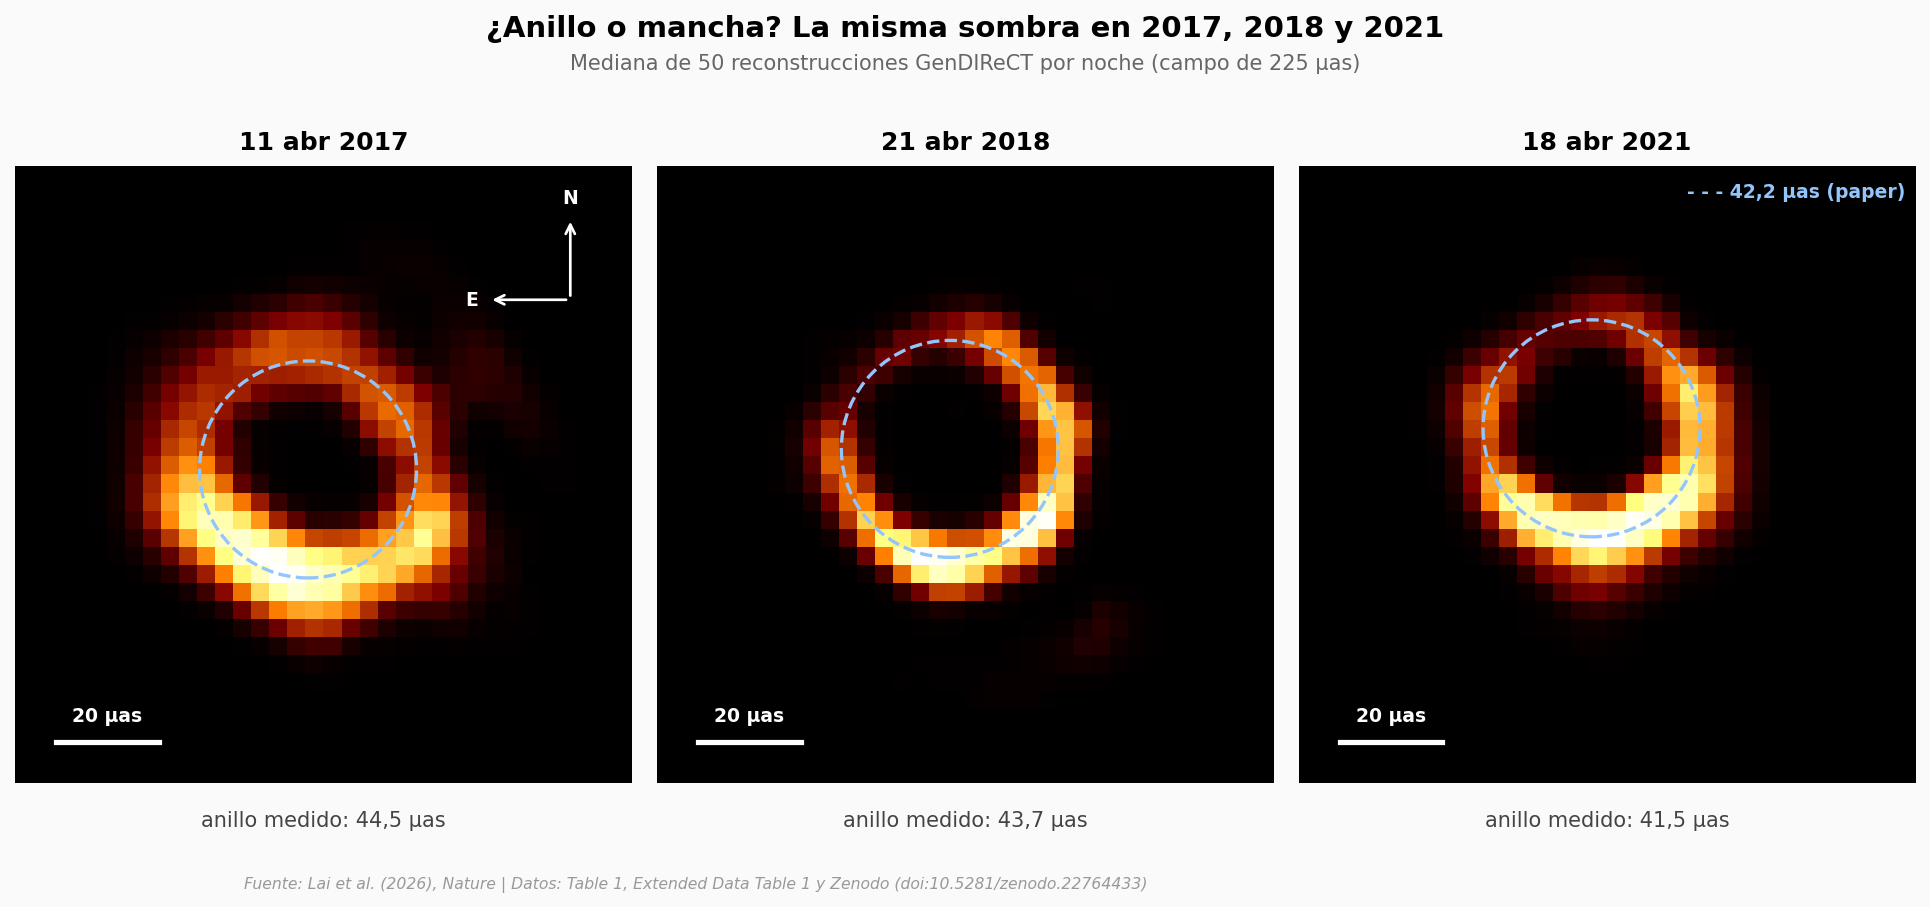

Diámetro medido sobre la imagen mediana vs Table 1 del paper (misma noche):
  2017-04-11: 44,5 μas  vs  43,3 ± 1,0  (+1,2 μas, +2,8 %; medio píxel = 1,76 μas) · ángulo del lado brillante (Table 1): 167°
  2018-04-21: 43,7 μas  vs  42,7 ± 0,5  (+1,0 μas, +2,4 %; medio píxel = 1,76 μas) · ángulo del lado brillante (Table 1): 205°
  2021-04-18: 41,5 μas  vs  39,9 ± 1,8  (+1,6 μas, +4,0 %; medio píxel = 1,76 μas) · ángulo del lado brillante (Table 1): 197°


In [2]:
ETIQUETA = {'2017-04-11': '11 abr 2017', '2018-04-21': '21 abr 2018', '2021-04-18': '18 abr 2021'}
MEDIO = FOV_UAS / 2
VENTANA = 60   # μas desde el centro que se muestran

ajustes = {}
fig, axes = plt.subplots(1, 3, figsize=(13, 5.2))
for ax, (fecha, cubo) in zip(axes, muestras.items()):
    mediana = np.median(cubo, axis=0)               # mediana píxel a píxel de las 50 reconstrucciones
    aj = ajusta_anillo(mediana)
    ajustes[fecha] = aj
    # Norte arriba, este a la izquierda (convención del cielo); brillo normalizado por noche
    ax.imshow(mediana / mediana.max(), cmap='afmhot', origin='upper',
              extent=[MEDIO, -MEDIO, -MEDIO, MEDIO], vmin=0, vmax=1)
    cx, cy = -aj['dx'], -aj['dy']                   # centro del anillo en coordenadas del cielo
    ax.add_patch(Circle((cx, cy), DIAM_PAPER / 2, fill=False, ls='--', lw=1.6, color='#93C5FD'))
    ax.set_xlim(VENTANA, -VENTANA)
    ax.set_ylim(-VENTANA, VENTANA)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(ETIQUETA[fecha], fontsize=12, fontweight='bold', pad=8)
    ax.text(0.5, -0.07, 'anillo medido: ' + es(f'{aj["diametro"]:.1f}') + ' μas',
            transform=ax.transAxes, ha='center', fontsize=10, color='#444444')
    # barra de escala de 20 μas
    ax.plot([52, 32], [-52, -52], color='white', lw=2.5)
    ax.text(42, -48, '20 μas', color='white', ha='center', fontsize=9, fontweight='bold')

axes[0].annotate('', xy=(-48, 50), xytext=(-48, 34), arrowprops=dict(arrowstyle='->', color='white', lw=1.3))
axes[0].annotate('', xy=(-32, 34), xytext=(-48, 34), arrowprops=dict(arrowstyle='->', color='white', lw=1.3))
axes[0].text(-48, 52, 'N', color='white', ha='center', va='bottom', fontsize=9, fontweight='bold')
axes[0].text(-30, 34, 'E', color='white', ha='right', va='center', fontsize=9, fontweight='bold')
axes[2].text(-58, 54, '- - - 42,2 μas (paper)', color='#93C5FD', fontsize=9, ha='right', fontweight='bold')

plt.tight_layout()
fig.suptitle('¿Anillo o mancha? La misma sombra en 2017, 2018 y 2021',
             fontsize=14, fontweight='bold', y=1.09)
fig.text(0.5, 1.02, 'Mediana de 50 reconstrucciones GenDIReCT por noche (campo de 225 μas)',
         fontsize=10, color='#666666', ha='center')
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/sombra_tres_anios.png', dpi=200, bbox_inches='tight')
plt.show()

pr('Diámetro medido sobre la imagen mediana vs Table 1 del paper (misma noche):')
for fecha, aj in ajustes.items():
    t1 = img.loc[img.fecha == fecha].iloc[0]
    pr(f'  {fecha}: {aj["diametro"]:.1f} μas  vs  {t1.diametro_uas} ± {t1.diametro_err_uas}  '
       f'(+{aj["diametro"] - t1.diametro_uas:.1f} μas, +{(aj["diametro"] / t1.diametro_uas - 1) * 100:.1f} %; medio píxel = {PIX / 2:.2f} μas) · ángulo del lado brillante (Table 1): '
       f'{t1.orientacion_deg}°')

El anillo se repite: en tres noches separadas por cuatro años sale un anillo con el hueco oscuro al centro, y el círculo de 42,2 μas del paper cae sobre el borde brillante. Los autores lo resumen diciendo que reproducen la morfología de anillo «sin ambigüedad» (*unequivocally*).

Medido por nosotros sobre estas medianas, el anillo da 44,5 μas en 2017, 43,7 en 2018 y 41,5 en 2021: entre un 2 y un 4 % más que la Table 1 para esas mismas noches (43,3; 42,7 y 39,9). La diferencia puede venir de que el paper promedia tres campos de visión y unas 300 reconstrucciones por noche (aquí hay un solo campo y 50) o de que nuestro ajuste es una versión simplificada del suyo; con estos datos no se pueden separar. En todo caso son entre 1,0 y 1,6 μas: menos de medio píxel (cada píxel mide 3,52 μas).

El lado más brillante queda al sur en las tres noches, pero no siempre en el mismo punto: la Table 1 da 167° el 11 de abril de 2017 (un poco al este del sur), 205° el 21 de abril de 2018 y 197° el 18 de abril de 2021 (al oeste del sur), medidos desde el norte girando hacia el este.

## ¿Y si el tamaño lo pone el método?

El paper mide el anillo de dos formas distintas: sobre las imágenes reconstruidas (Table 1) y ajustando un anillo geométrico directamente a los invariantes de cierre, sin pasar por ninguna imagen (Extended Data Table 1). Pongamos las ocho noches lado a lado.

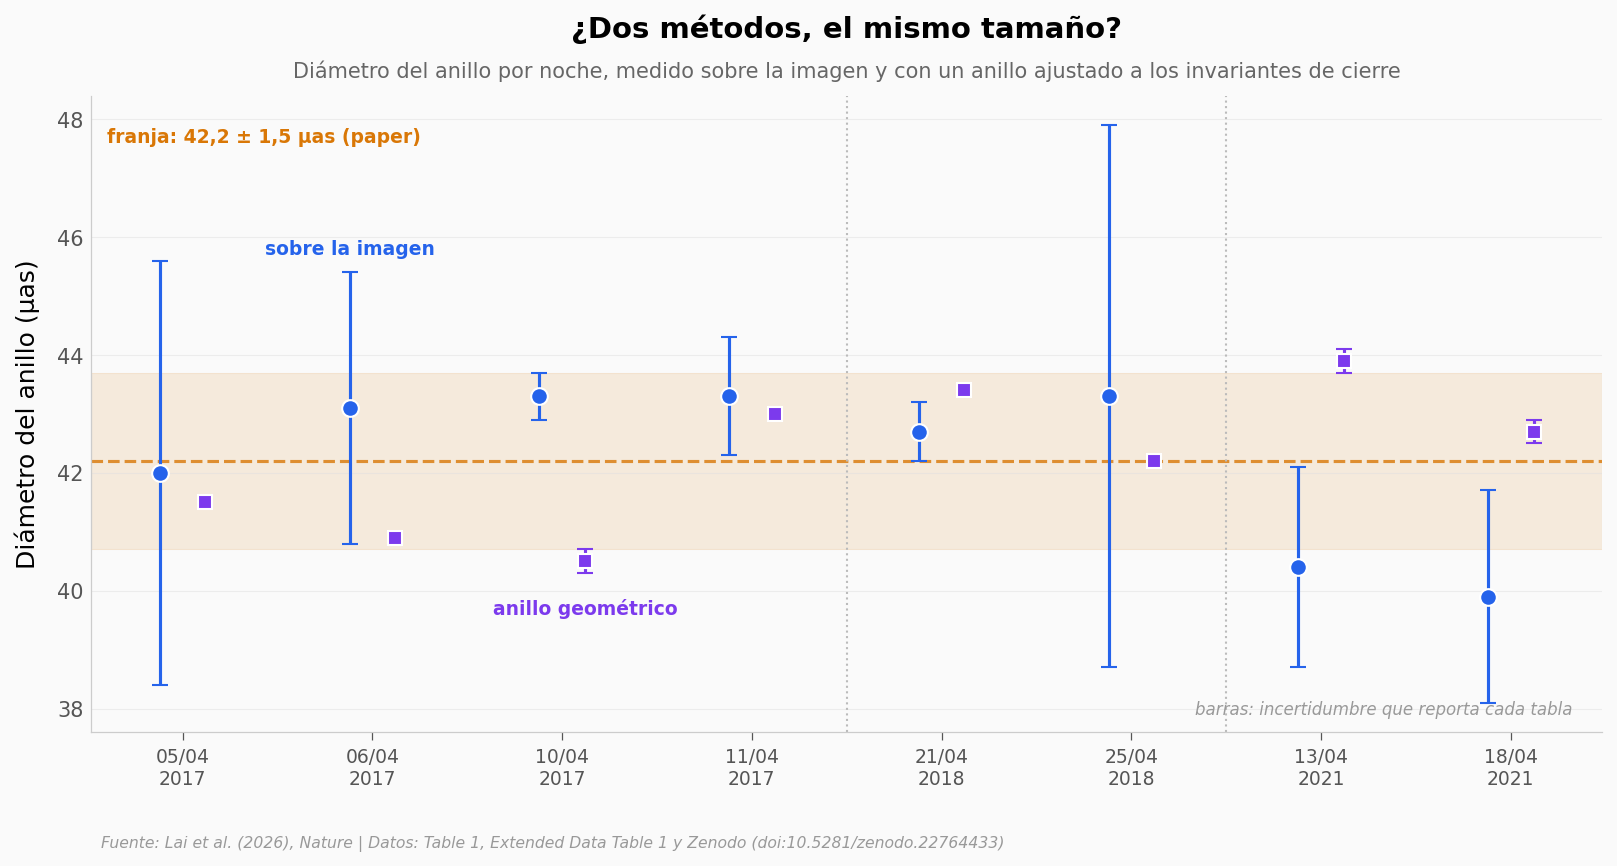

Media de las 8 noches — imagen: 42,25 μas (desv. est. 1,38) · geométrico: 42,26 μas (desv. est. 1,21)
Diferencia de medias: 0,01 μas
Mayor diferencia en una noche: 3,5 μas el 2021-04-13 (imagen 40,4 · geométrico 43,9)
Rango de los 16 valores: 39,9–43,9 μas
¿Ordenan las noches igual? Spearman ρ = −0,41 (p = 0,31, n = 8)


In [3]:
x = np.arange(len(img))
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.axhspan(DIAM_PAPER - ERR_PAPER, DIAM_PAPER + ERR_PAPER, color=COLOR_REFERENCIA, alpha=0.12, zorder=0)
ax.axhline(DIAM_PAPER, color=COLOR_REFERENCIA, lw=1.5, ls='--', alpha=0.8)
ax.text(-0.4, 47.6, 'franja: ' + es(f'{DIAM_PAPER} ± {ERR_PAPER}') + ' μas (paper)',
        color=COLOR_REFERENCIA, fontsize=9, fontweight='bold', ha='left')
ax.errorbar(x - 0.12, img.diametro_uas, yerr=img.diametro_err_uas, fmt='o', color=COLOR_DATOS,
            ms=8, capsize=4, lw=1.5, zorder=5, markeredgecolor='white')
ax.errorbar(x + 0.12, geo.diametro_uas, yerr=geo.diametro_err_uas, fmt='s', color=COLOR_GEO,
            ms=7, capsize=4, lw=1.5, zorder=5, markeredgecolor='white')
ax.text(1 - 0.12, img.diametro_uas[1] + img.diametro_err_uas[1] + 0.3, 'sobre la imagen',
        color=COLOR_DATOS, fontsize=9, fontweight='bold', ha='center')
ax.text(2 + 0.12, geo.diametro_uas[2] - 0.9, 'anillo geométrico', color=COLOR_GEO, fontsize=9,
        fontweight='bold', ha='center')
for xc in (3.5, 5.5):
    ax.axvline(xc, color=COLOR_GRIS, lw=1, ls=':')
ax.set_xticks(x)
ax.set_xticklabels([f'{d[8:]}/{d[5:7]}\n{d[:4]}' for d in img.fecha], fontsize=9)
ax.set_ylabel('Diámetro del anillo (μas)')
ax.yaxis.set_major_formatter(COMA)
ax.set_title('¿Dos métodos, el mismo tamaño?', fontsize=14, fontweight='bold', pad=28)
ax.text(0.5, 1.03, 'Diámetro del anillo por noche, medido sobre la imagen y con un anillo ajustado a los invariantes de cierre',
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
ax.text(0.98, 0.02, 'barras: incertidumbre que reporta cada tabla', transform=ax.transAxes,
        fontsize=8, color='#999999', ha='right', va='bottom', style='italic')
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/diametro_dos_metodos.png', dpi=200, bbox_inches='tight')
plt.show()

dif = img.diametro_uas.values - geo.diametro_uas.values
i_max = np.abs(dif).argmax()
pr(f'Media de las 8 noches — imagen: {img.diametro_uas.mean():.2f} μas (desv. est. {img.diametro_uas.std(ddof=1):.2f}) · '
   f'geométrico: {geo.diametro_uas.mean():.2f} μas (desv. est. {geo.diametro_uas.std(ddof=1):.2f})')
pr(f'Diferencia de medias: {abs(img.diametro_uas.mean() - geo.diametro_uas.mean()):.2f} μas')
pr(f'Mayor diferencia en una noche: {abs(dif[i_max]):.1f} μas el {img.fecha[i_max]} '
   f'(imagen {img.diametro_uas[i_max]} · geométrico {geo.diametro_uas[i_max]})')
todos = np.concatenate([img.diametro_uas, geo.diametro_uas])
pr(f'Rango de los 16 valores: {todos.min()}–{todos.max()} μas')
rho, p = stats.spearmanr(img.diametro_uas, geo.diametro_uas)
pr(f'¿Ordenan las noches igual? Spearman ρ = {rho:.2f} (p = {p:.2f}, n = {len(img)})')

En promedio, los dos métodos coinciden: 42,25 μas sobre la imagen y 42,26 con el anillo geométrico (el paper da 42,2 ± 1,5 y 42,3 ± 1,1). Noche por noche ya no tanto: el 13 de abril de 2021 la imagen da 40,4 μas y el anillo geométrico 43,9, una diferencia de 3,5. Y no ordenan las noches igual (ρ = −0,41, p = 0,31, n = 8). Lo robusto es el promedio, no el valor de cada noche.

Un detalle: la dispersión entre las ocho noches que calculamos es 1,38 μas (desviación estándar), no 1,5. El paper la llama desviación estándar pero no dice sobre qué valores, así que el ± 1,5 queda como suyo.

## Del tamaño a la masa

El anillo es la sombra de un agujero negro de cierta masa a cierta distancia. La cuenta tiene dos pasos: el radio gravitacional aparente (la escala natural de tamaño del agujero negro, GM/c², vista en el cielo) es θg = d / α, y la masa es M = θg · D · c² / G. La distancia D = 16,8 Mpc viene de otras medidas, y el factor α ≈ 11 lo calibró el EHT con simulaciones. Veamos qué masa sale del 42,2 y cómo queda frente a las dos medidas previas: la que sale de la velocidad de las estrellas y la que sale del gas.

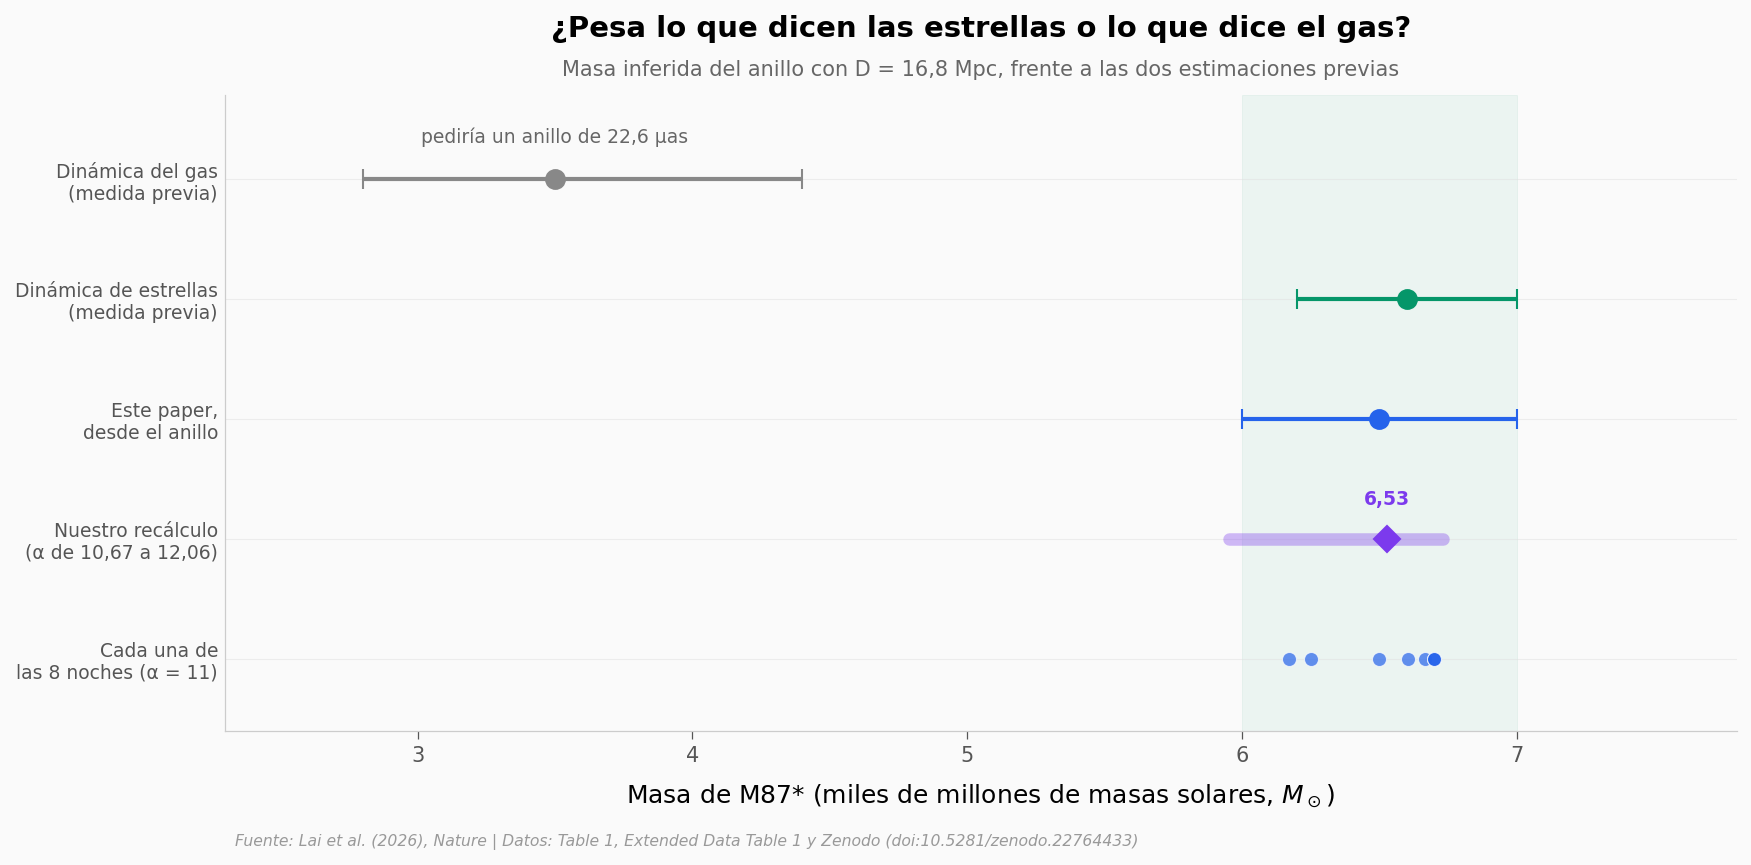

Radio gravitacional aparente: 42,2 / 11,0 = 3,84 μas
Masa con α = 11,0 y D = 16,8 Mpc: 6,53 × 10⁹ M☉  (paper: 6,5 ± 0,5)
Con α de 10,67 a 12,06: 5,95 a 6,73 × 10⁹ M☉  (paper: 6,0–6,7)
Con D de 16,1 a 17,6 Mpc: 6,26 a 6,84 × 10⁹ M☉
Noche por noche (α = 11): de 6,17 a 6,70 × 10⁹ M☉
Anillo esperado con la masa del gas (3,5): 22,6 μas · con la de las estrellas (6,6): 42,7 μas


In [4]:
M_nominal = masa(DIAM_PAPER)
M_alfa = (masa(DIAM_PAPER, alfa=12.06), masa(DIAM_PAPER, alfa=10.67))
M_noches = masa(img.diametro_uas.values)
d_gas, d_estrellas = diametro(3.5), diametro(6.6)

filas = ['Dinámica del gas\n(medida previa)', 'Dinámica de estrellas\n(medida previa)',
         'Este paper,\ndesde el anillo', 'Nuestro recálculo\n(α de 10,67 a 12,06)', 'Cada una de\nlas 8 noches (α = 11)']
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.errorbar(3.5, 4, xerr=[[0.7], [0.9]], fmt='o', color='#888888', ms=9, capsize=5, lw=2)
ax.errorbar(6.6, 3, xerr=0.4, fmt='o', color=COLOR_ESTRELLAS, ms=9, capsize=5, lw=2)
ax.errorbar(6.5, 2, xerr=0.5, fmt='o', color=COLOR_DATOS, ms=9, capsize=5, lw=2)
ax.plot(M_alfa, [1, 1], color=COLOR_GEO, lw=6, alpha=0.35, solid_capstyle='round')
ax.plot(M_nominal, 1, 'D', color=COLOR_GEO, ms=9)
ax.scatter(M_noches, np.zeros_like(M_noches), color=COLOR_DATOS, s=45, alpha=0.7,
           edgecolors='white', linewidths=0.5, zorder=5)
ax.axvspan(6.0, 7.0, color=COLOR_ESTRELLAS, alpha=0.06, zorder=0)
ax.text(M_nominal, 1.28, es(f'{M_nominal:.2f}'), color=COLOR_GEO, fontsize=9, fontweight='bold', ha='center')
ax.text(3.5, 4.3, 'pediría un anillo de ' + es(f'{d_gas:.1f}') + ' μas', color='#666666', fontsize=9, ha='center')
ax.set_yticks(range(5))
ax.set_yticklabels(filas[::-1], fontsize=9)
ax.set_ylim(-0.6, 4.7)
ax.set_xlim(2.3, 7.8)
ax.xaxis.set_major_formatter(COMA)
ax.set_xlabel(r'Masa de M87* (miles de millones de masas solares, $M_\odot$)')
ax.set_title('¿Pesa lo que dicen las estrellas o lo que dice el gas?', fontsize=14, fontweight='bold', pad=28)
ax.text(0.5, 1.03, 'Masa inferida del anillo con D = 16,8 Mpc, frente a las dos estimaciones previas',
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/masa_m87.png', dpi=200, bbox_inches='tight')
plt.show()

pr(f'Radio gravitacional aparente: {DIAM_PAPER} / {ALFA} = {DIAM_PAPER / ALFA:.2f} μas')
pr(f'Masa con α = {ALFA} y D = {DIST_MPC} Mpc: {M_nominal:.2f} × 10⁹ M☉  (paper: 6,5 ± 0,5)')
pr(f'Con α de 10,67 a 12,06: {M_alfa[0]:.2f} a {M_alfa[1]:.2f} × 10⁹ M☉  (paper: 6,0–6,7)')
pr(f'Con D de 16,1 a 17,6 Mpc: {masa(DIAM_PAPER, dist_mpc=16.1):.2f} a {masa(DIAM_PAPER, dist_mpc=17.6):.2f} × 10⁹ M☉')
pr(f'Noche por noche (α = 11): de {M_noches.min():.2f} a {M_noches.max():.2f} × 10⁹ M☉')
pr(f'Anillo esperado con la masa del gas (3,5): {d_gas:.1f} μas · con la de las estrellas (6,6): {d_estrellas:.1f} μas')

Con α = 11 y D = 16,8 Mpc, el anillo de 42,2 μas se traduce en 6,53 mil millones de soles. Si movemos α por todo su rango calibrado (10,67 a 12,06), la masa va de 5,95 a 6,73: el paper da 6,5 ± 0,5. Encaja con la estimación de las estrellas (6,6 ± 0,4) y queda lejos de la del gas (3,5): con esa masa y el mismo α, el anillo tendría que medir unos 22,6 μas, poco más de la mitad.

Ojo: la masa no se mide directamente. Es una inferencia que hereda los supuestos de α (salido de simulaciones) y de D. El paper también dice que la imagen encaja mejor con una inclinación de unos 20° respecto al chorro (*jet*) de materia que M87\* lanza hacia nuestro lado; eso sale de compararla con simulaciones y no lo podemos reproducir aquí.

## ¿Qué tan lejos queda el anillo «liviano»?

Miremos las 150 reconstrucciones una por una: ¿alguna se acerca a los 22,6 μas que pediría la masa del gas?

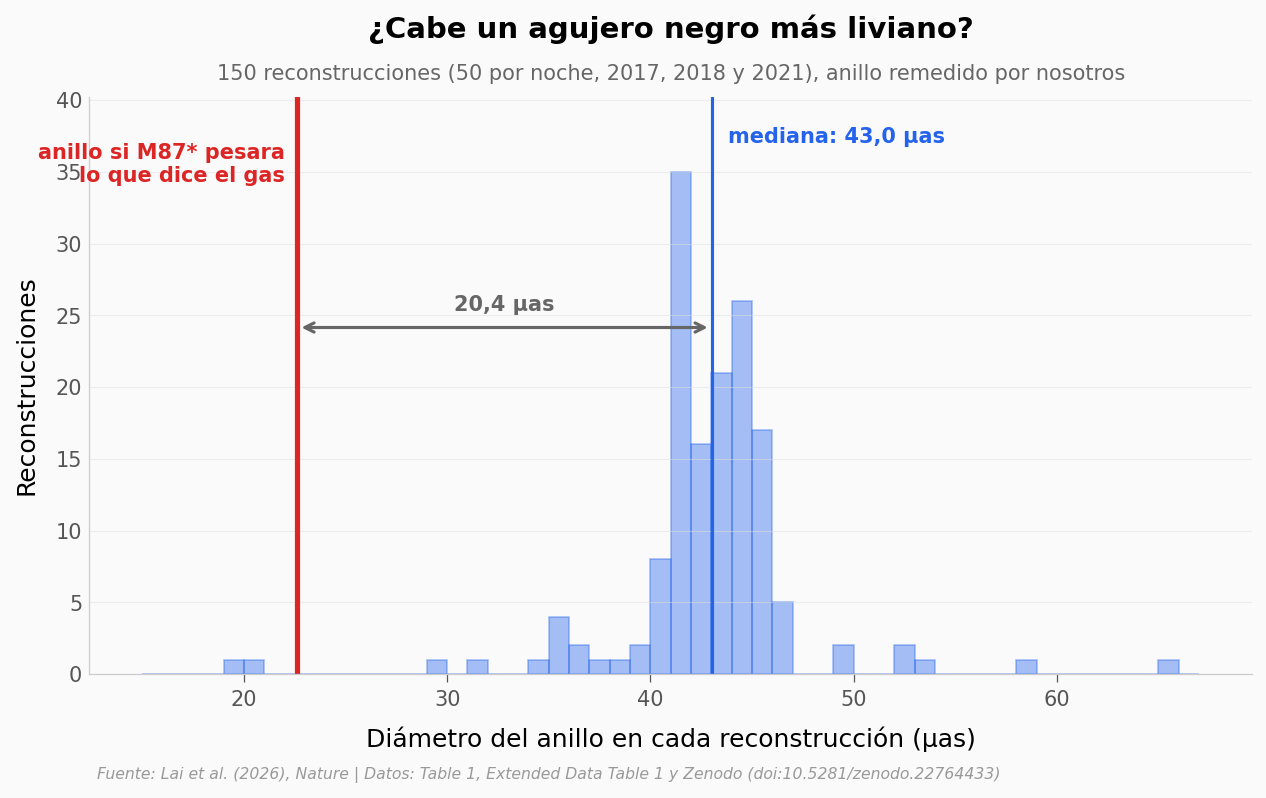

150 reconstrucciones: mediana 43,0 μas, IQR 41,4–44,7, media 42,8
Entre 38 y 46 μas: 126 de 150 (84 %)
Por debajo de 35 μas: 5 · la más chica: 19,4 μas · la más grande: 65,7 μas
Más cerca de 22,6 que de 42,2: 4 de 150
Forma: asimetría −0,70, curtosis (exceso) 10,1 — colas largas
  2017-04-11: mediana 44,6 μas (n = 50)
  2018-04-21: mediana 43,7 μas (n = 50)
  2021-04-18: mediana 41,4 μas (n = 50)


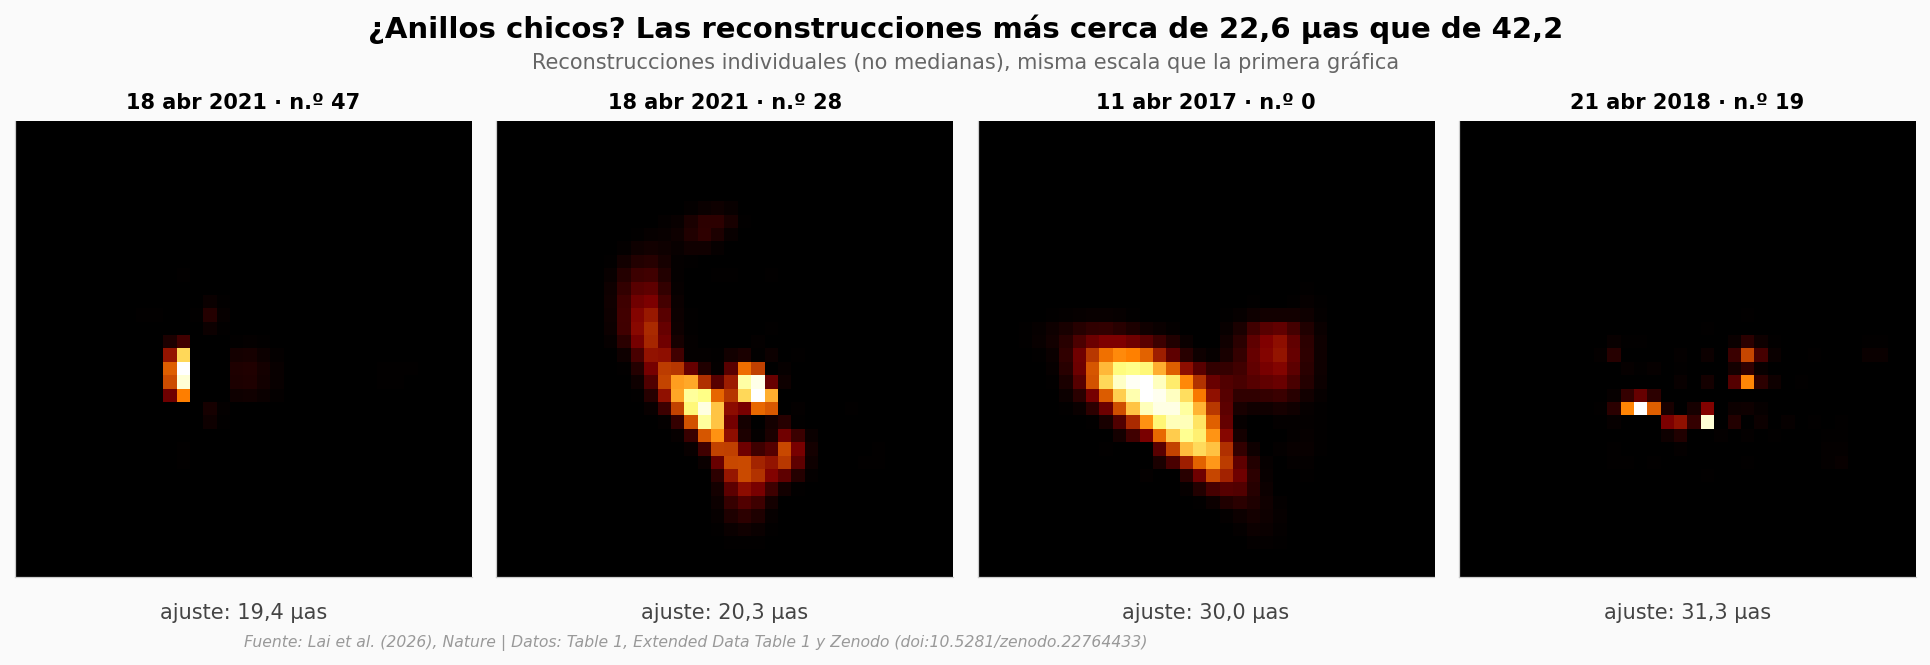

Reconstrucciones más cerca de 22,6 que de 42,2 μas: 4 — 2021-04-18 n.º 47 (19,4), 2021-04-18 n.º 28 (20,3), 2017-04-11 n.º 0 (30,0), 2018-04-21 n.º 19 (31,3)


In [5]:
d = muestras_d.diametro_uas.values
med = np.median(d)
q1, q3 = np.percentile(d, [25, 75])

fig, ax = plt.subplots(figsize=(10, 5))
n, bins, patches = ax.hist(d, bins=np.arange(15, 68, 1), color=COLOR_DATOS, alpha=0.4,
                           edgecolor=COLOR_DATOS, linewidth=0.8)
y_max = n.max() * 1.15
ax.set_ylim(0, y_max)
ax.axvline(med, color=COLOR_DATOS, linewidth=1.5)
ax.axvline(d_gas, color=COLOR_ALERTA, linewidth=2.5)
ax.annotate('', xy=(d_gas, y_max * 0.6), xytext=(med, y_max * 0.6),
            arrowprops=dict(arrowstyle='<->', color='#666666', lw=1.5))
ax.text((d_gas + med) / 2, y_max * 0.63, es(f'{med - d_gas:.1f}') + ' μas', ha='center',
        fontsize=10, color='#666666', fontweight='bold')
ax.text(med + 0.8, y_max * 0.92, 'mediana: ' + es(f'{med:.1f}') + ' μas', color=COLOR_DATOS,
        fontsize=10, fontweight='bold')
ax.text(d_gas - 0.6, y_max * 0.92, 'anillo si M87* pesara\nlo que dice el gas', color=COLOR_ALERTA,
        fontsize=10, fontweight='bold', ha='right', va='top')
ax.set_xlabel('Diámetro del anillo en cada reconstrucción (μas)')
ax.set_ylabel('Reconstrucciones')
ax.xaxis.set_major_formatter(COMA)
ax.set_title('¿Cabe un agujero negro más liviano?', fontsize=14, fontweight='bold', pad=28)
ax.text(0.5, 1.03, '150 reconstrucciones (50 por noche, 2017, 2018 y 2021), anillo remedido por nosotros',
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/histograma_diametros.png', dpi=200, bbox_inches='tight')
plt.show()

pr(f'150 reconstrucciones: mediana {med:.1f} μas, IQR {q1:.1f}–{q3:.1f}, media {d.mean():.1f}')
pr(f'Entre 38 y 46 μas: {((d >= 38) & (d <= 46)).sum()} de {len(d)} ({((d >= 38) & (d <= 46)).mean() * 100:.0f} %)')
pr(f'Por debajo de 35 μas: {(d < 35).sum()} · la más chica: {d.min():.1f} μas · la más grande: {d.max():.1f} μas')
pr(f'Más cerca de {d_gas:.1f} que de {DIAM_PAPER}: {(np.abs(d - d_gas) < np.abs(d - DIAM_PAPER)).sum()} de {len(d)}')
pr(f'Forma: asimetría {stats.skew(d):.2f}, curtosis (exceso) {stats.kurtosis(d):.1f} — colas largas')
for f, g in muestras_d.groupby('fecha'):
    pr(f'  {f}: mediana {g.diametro_uas.median():.1f} μas (n = {len(g)})')

# Las reconstrucciones que quedan más cerca del anillo «del gas»: ¿son anillos pequeños?
cerca = muestras_d[np.abs(d - d_gas) < np.abs(d - DIAM_PAPER)].sort_values('diametro_uas')
fig, axes = plt.subplots(1, len(cerca), figsize=(13, 3.6))
for ax, (_, fila) in zip(np.atleast_1d(axes), cerca.iterrows()):
    im = muestras[fila.fecha][int(fila.muestra)]
    ax.imshow(im / im.max(), cmap='afmhot', origin='upper', extent=[MEDIO, -MEDIO, -MEDIO, MEDIO], vmin=0, vmax=1)
    ax.set_xlim(VENTANA, -VENTANA); ax.set_ylim(-VENTANA, VENTANA)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(ETIQUETA[fila.fecha] + ' · n.º ' + str(int(fila.muestra)), fontsize=10, pad=6)
    ax.text(0.5, -0.09, 'ajuste: ' + es(f'{fila.diametro_uas:.1f}') + ' μas', transform=ax.transAxes,
            ha='center', fontsize=10, color='#444444')
plt.tight_layout()
fig.suptitle('¿Anillos chicos? Las reconstrucciones más cerca de 22,6 μas que de 42,2',
             fontsize=14, fontweight='bold', y=1.12)
fig.text(0.5, 1.02, 'Reconstrucciones individuales (no medianas), misma escala que la primera gráfica',
         fontsize=10, color='#666666', ha='center')
fig.text(0.13, -0.05, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/reconstrucciones_extremas.png', dpi=200, bbox_inches='tight')
plt.show()
pr(f'Reconstrucciones más cerca de {d_gas:.1f} que de {DIAM_PAPER} μas: {len(cerca)} — ' +
   ', '.join(f'{r.fecha} n.º {int(r.muestra)} ({r.diametro_uas:.1f})' for _, r in cerca.iterrows()))

El 84 % de las reconstrucciones cae entre 38 y 46 μas, con mediana de 43,0 (IQR 41,4–44,7). Pero hay cola: 4 de las 150 quedan más cerca de los 22,6 μas del gas que de los 42,2 del paper, y la más chica da 19,4. Al abrirlas no aparecen anillos chicos: son manchas, puntos o fragmentos sueltos, sin un anillo cerrado, y el «diámetro» que les mide el ajuste no corresponde a ningún anillo. Según el paper, las reconstrucciones que no son claramente anillos suelen ser escasas frente al grueso y ajustan peor los datos, y la mediana resiste mejor esos casos atípicos; por eso no se apoya en una reconstrucción suelta: resume cientos con su mediana.

Cuidado con leer esto como 150 observaciones. Son 50 reconstrucciones del mismo algoritmo sobre cada una de tres noches: su dispersión dice cuánto varía el método con los mismos datos, no cuánto cambia el cielo.

### Lo que los datos soportan

| Afirmación | ¿Soportada? | Detalle |
|------------|-------------|---------|
| El anillo reaparece en las tres noches que podemos abrir | ✅ | Medianas de 50 reconstrucciones del 11/04/2017, 21/04/2018 y 18/04/2021: anillo con hueco central en las tres. Las otras cinco noches solo están en las tablas del paper |
| El diámetro medio de las ocho noches es 42,2 μas | ✅ | Media de la Table 1: 42,25 μas (n = 8). La dispersión entre noches es 1,38 μas (desv. est.), algo menor que el ± 1,5 del paper, que la llama desviación estándar sin decir sobre qué valores |
| El anillo geométrico da el mismo tamaño medio | ✅ | 42,26 μas frente a 42,25: diferencia de 0,01. Pero noche por noche difieren hasta 3,5 μas y no ordenan las noches igual (ρ = −0,41, p = 0,31, n = 8) |
| La masa inferida es de unos 6.500 millones de soles | ⚠️ | Recalculada: 6,53 × 10⁹ con α = 11 y D = 16,8 Mpc; de 5,95 a 6,73 con α de 10,67 a 12,06. Es inferencia: depende de α (simulaciones) y de D |
| La masa encaja con la de las estrellas y no con la del gas | ⚠️ | Hereda los supuestos de la masa: estrellas 6,6 ± 0,4; gas 3,5. Con α de 10,67 a 12,06 la masa va de 5,95 a 6,73; para llegar a la del gas haría falta α ≈ 20,5 (celda experimental), fuera del rango calibrado |
| La imagen encaja con una inclinación de unos 20° | ⚠️ | Lo dice el paper comparando con simulaciones; no se puede reproducir con estos datos |

> **Limitaciones:** solo tenemos 50 reconstrucciones por noche, para 3 de las 8 noches y un campo de visión (225 μas); el paper usa unas 300 por noche y tres campos. Nuestro ajuste de anillo es una versión simplificada del de los autores, y nuestras medidas dan diámetros entre un 2 y un 4 % mayores que la Table 1, sin que podamos separar si es por el ajuste o por la muestra. El ancho del anillo y el brillo central dependen mucho del método (el propio paper dice que probablemente no reflejan propiedades de la fuente), así que no los usamos. La Extended Data Table 1 está transcrita a mano desde una imagen del paper.

## Ahora tú

1. **¿Qué valor de α haría falta para que el anillo de 42,2 μas diera la masa del gas?** Pista: `ALFA = DIAM_PAPER / (diametro(3.5) / 11)`.
2. **¿Cuánto se mueve la masa si M87 estuviera a 16,1 o a 17,6 Mpc?** Pista: cambia `DIST_MPC` en la celda de configuración y vuelve a ejecutar.
3. **¿Cambia el anillo si resumes las 50 reconstrucciones con la media en vez de la mediana?** Pista: `ajusta_anillo(muestras['2021-04-18'].mean(axis=0))` y compáralo con los 41,5 μas de la mediana.

α necesario: 20,5  (rango calibrado por el EHT: 10,67–12,06)


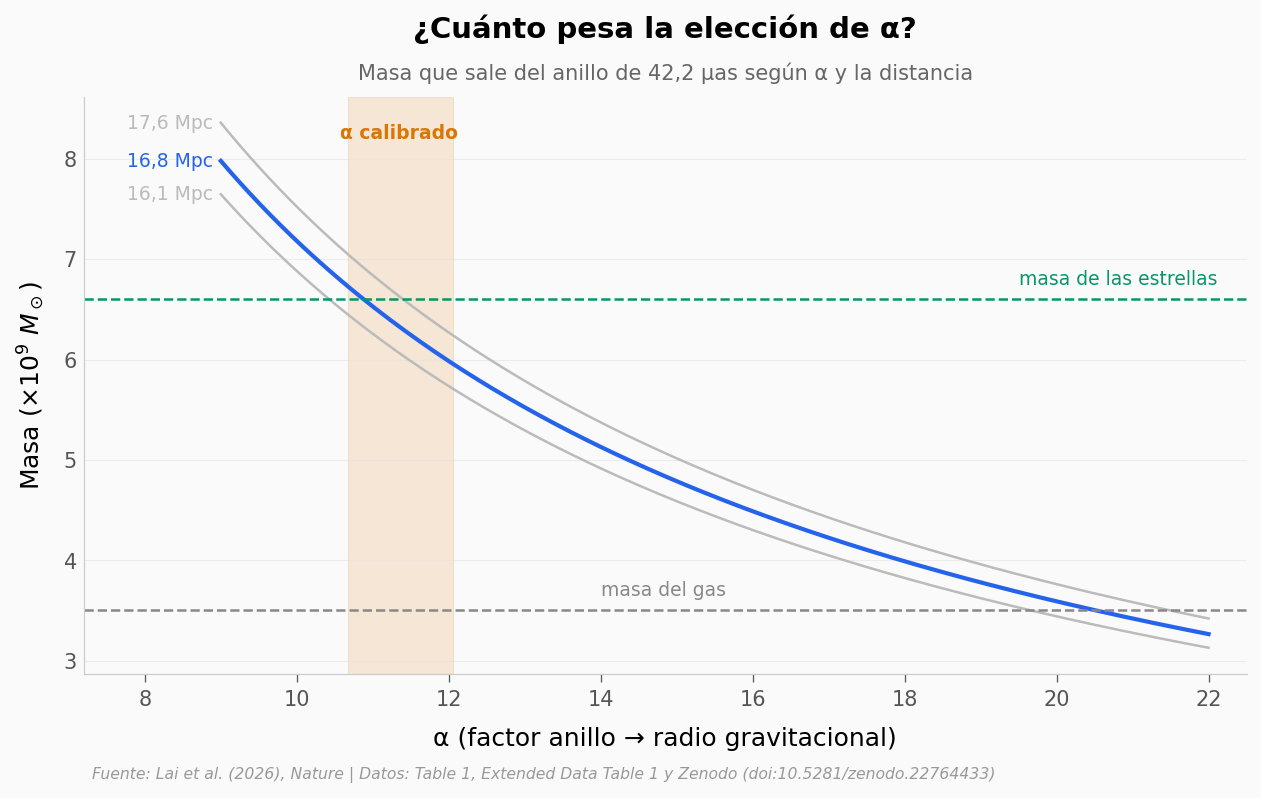

In [6]:
# --- EXPERIMENTA AQUÍ ---
# ¿Qué α haría falta para que el anillo de 42,2 μas diera la masa del gas (3,5 × 10⁹ M☉)?
alfa_gas = DIAM_PAPER / (diametro(3.5) / ALFA)
pr(f'α necesario: {alfa_gas:.1f}  (rango calibrado por el EHT: 10,67–12,06)')

alfas = np.linspace(9, 22, 200)
fig, ax = plt.subplots(figsize=(10, 5))
for dist, color in [(16.1, COLOR_GRIS), (16.8, COLOR_DATOS), (17.6, COLOR_GRIS)]:
    ax.plot(alfas, masa(DIAM_PAPER, alfa=alfas, dist_mpc=dist), color=color, lw=2 if dist == 16.8 else 1.2)
    ax.text(8.9, masa(DIAM_PAPER, alfa=9, dist_mpc=dist), es(f'{dist} Mpc'), color=color, fontsize=9,
            va='center', ha='right')
ax.axvspan(10.67, 12.06, color=COLOR_REFERENCIA, alpha=0.15)
ax.text(11.35, 8.2, 'α calibrado', color=COLOR_REFERENCIA, fontsize=9, ha='center', fontweight='bold')
ax.axhline(3.5, color='#888888', ls='--', lw=1.2)
ax.text(14, 3.65, 'masa del gas', color='#888888', fontsize=9)
ax.axhline(6.6, color=COLOR_ESTRELLAS, ls='--', lw=1.2)
ax.text(19.5, 6.75, 'masa de las estrellas', color=COLOR_ESTRELLAS, fontsize=9)
ax.set_xlim(7.2, 22.5)
ax.set_xlabel('α (factor anillo → radio gravitacional)')
ax.set_ylabel(r'Masa ($\times 10^9\ M_\odot$)')
ax.xaxis.set_major_formatter(COMA)
ax.yaxis.set_major_formatter(COMA)
ax.set_title('¿Cuánto pesa la elección de α?', fontsize=14, fontweight='bold', pad=28)
ax.text(0.5, 1.03, 'Masa que sale del anillo de 42,2 μas según α y la distancia',
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/masa_segun_alfa.png', dpi=200, bbox_inches='tight')
plt.show()

## Créditos

**Paper:** Lai et al. (2026). *Independent interferometric observable confirms black hole shadow in M87\**. Nature. DOI: [10.1038/s41586-026-11241-9](https://doi.org/10.1038/s41586-026-11241-9) · Acceso abierto (CC BY 4.0).

**Datos:** diámetros por noche transcritos de la Table 1 (medidos sobre las imágenes) y de la Extended Data Table 1 (anillo geométrico) del paper; 150 reconstrucciones de M87\* del repositorio GenDIReCT en Zenodo ([doi:10.5281/zenodo.22764433](https://doi.org/10.5281/zenodo.22764433), licencia MIT), con el diámetro remedido por nosotros en cada una. Los datos originales son del EHT, de sus campañas de observación de 2017, 2018 y 2021.

**Repositorio:** [Ciencia-a-Mordiscos/lab](https://github.com/Ciencia-a-Mordiscos/lab)

## Fuentes

**Paper**: [Independent interferometric observable confirms black hole shadow in M87*](https://doi.org/10.1038/s41586-026-11241-9)  
*Nature, 2026-11-11*

**Datos**: [samlaihei/GenDIReCT: GenDIReCT_v1.1.0-paperM87](https://doi.org/10.5281/zenodo.22764433)  
*Zenodo, 2026-09-15* — 150 reconstrucciones de M87\* (2017, 2018, 2021)

*22 afirmaciones del notebook verificadas contra estas fuentes*